# Analyse non supervisée et labels faibles

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 3 - Réalisez une analyse non supervisée  
**Auteur :** Kilian Lefevre  

---

## Objectif du notebook

Les caractéristiques extraites à l'étape précédente servent à **regrouper les images**, puis à attribuer un **label faible** aux images non annotées. Ce notebook répond aux questions suivantes :

- Comment réserver un jeu de test et un jeu de validation avant toute transformation des features ?
- Les images forment-elles deux groupes visibles après réduction de dimension ?
- Que donnent K-Means, DBSCAN et HDBSCAN, comparés aux labels forts ?
- Que capturent les clusters : la pathologie, ou des indices liés à l'acquisition ?
- Les labels faibles sont-ils assez fiables pour l'étape suivante ?

**Prérequis :** le manifeste dédupliqué (`data/interim/manifest.csv`) et les features (`data/processed/features_resnet50_layer{3,4}.npz`), produits par `make data` et `make features`.

## 1. Chargement

On charge le manifeste et les deux matrices de features (`layer3`, 1 024 dimensions, et `layer4`, 2 048 dimensions). L'alignement avec les `image_id` du manifeste est vérifié.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors

from brain_mri.config import FIGURES_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR
from brain_mri.dataset import read_manifest, split_dataset
from brain_mri.features import EXTRACTION_LAYERS, MODEL_NAME, load_features
from brain_mri.modeling.preprocessing import (
    N_COMPONENTS,
    RANDOM_STATE,
    reduce_with_pca,
    standardize,
)
from brain_mri.modeling.unsupervised import (
    REFERENCE_LAYER,
    ari_without_noise,
    build_weak_labels,
    encode_labels,
    evaluate_weak_labels,
    kmeans_confidence,
    majority_mapping,
    to_weak_labels,
)

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

manifest = read_manifest(INTERIM_DATA_DIR / "manifest.csv")

raw_features = {}
for layer in EXTRACTION_LAYERS:
    path = PROCESSED_DATA_DIR / f"features_{MODEL_NAME}_{layer}.npz"
    image_ids, matrix = load_features(path)
    assert (image_ids == manifest["image_id"].to_numpy()).all()
    raw_features[layer] = matrix
    print(
        f"{layer} : {matrix.shape[0]:,} images × {matrix.shape[1]:,} dimensions"
    )

2026-10-23 15:23:15.924 | INFO     | brain_mri.config:<module>:11 - PROJ_ROOT path is: /Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees


layer3 : 1,386 images × 1,024 dimensions
layer4 : 1,386 images × 2,048 dimensions


## 2. Découpage entraînement, validation et test

La standardisation, la PCA et le clustering **s'ajustent sur des données**. Si le jeu de test participait à cet ajustement, il ne serait plus « jamais vu ». On définit donc les trois jeux **avant** toute transformation :

- le **test** (30 images) sert à l'évaluation finale ;
- la **validation** (16 images) sert aux vérifications en cours de route et, à l'étape suivante, à l'arrêt anticipé de l'entraînement ;
- l'**entraînement** regroupe les 52 autres images annotées et **toutes les images non annotées**. C'est sur lui que s'ajustent la standardisation, la PCA et les clusterings.

Test et validation sont tirés **parmi les images annotées uniquement**, car il faut des labels forts pour les évaluer. Le tirage est **stratifié** : autant de `cancer` que de `normal`. Les images non annotées ne forment **aucune classe** : elles servent à l'apprentissage non supervisé.

Le découpage est implémenté dans `brain_mri.dataset` (`split_dataset`) et enregistré dans `data/processed/split.csv`, pour que l'étape suivante réutilise exactement les mêmes images.

In [2]:
split = split_dataset(manifest)
split.to_csv(PROCESSED_DATA_DIR / "split.csv", index=False)
manifest["split"] = split["split"].to_numpy()

is_train = (manifest["split"] == "train").to_numpy()
is_validation = (manifest["split"] == "validation").to_numpy()
is_test = (manifest["split"] == "test").to_numpy()
is_labeled = manifest["is_labeled"].to_numpy()
# Label fort : 1 = cancer, 0 = normal, NaN = image non annotée.
strong_label = encode_labels(manifest["label"])

summary = (
    manifest.assign(label=manifest["label"].fillna("non annotée"))
    .groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
    .loc[["train", "validation", "test"]]
)
summary["total"] = summary.sum(axis=1)
display(summary)

assert not (is_train & is_validation).any()
assert not (is_train & is_test).any()
assert not (is_validation & is_test).any()
assert is_labeled[is_validation | is_test].all()

label,cancer,non annotée,normal,total
split,,,,
train,27,1288,25,1340
validation,8,0,8,16
test,15,0,15,30


## 3. Standardisation

Chaque dimension est centrée et réduite (moyenne 0, écart-type 1), pour qu'aucune dimension de grande amplitude ne domine les distances. Le `StandardScaler` est **ajusté sur l'entraînement uniquement**, puis appliqué tel quel à la validation et au test. Cette étape est implémentée dans `brain_mri.modeling.preprocessing` (`standardize`).

In [3]:
is_held_out = ~is_train

scaled_features = {}
rows = []
for layer, matrix in raw_features.items():
    scaled = standardize(matrix, is_train)
    scaled_features[layer] = scaled
    rows.append(
        {
            "couche": layer,
            "moyenne entraînement": np.abs(scaled[is_train].mean(axis=0)).max(),
            "écart-type entraînement": scaled[is_train].std(axis=0).mean(),
            "moyenne hors entraînement": np.abs(
                scaled[is_held_out].mean(axis=0)
            ).mean(),
            "écart-type hors entraînement": scaled[is_held_out]
            .std(axis=0)
            .mean(),
        }
    )
display(pd.DataFrame(rows).set_index("couche").round(3))

,moyenne entraînement,écart-type entraînement,moyenne hors entraînement,écart-type hors entraînement
couche,,,,
layer3,0.0,1.0,0.268,1.029
layer4,0.0,1.0,0.161,0.860


Hors entraînement, les moyennes s'écartent de 0, surtout pour `layer3` : les images annotées ne suivent pas exactement la distribution des non annotées.

## 4. Réduction de dimension

Deux outils, avec deux rôles différents :

- La **PCA** est linéaire et reproductible. Elle sert à **visualiser** (deux premières composantes) et à **réduire** les features avant le clustering : en dimension 1 024 ou 2 048, les distances deviennent peu discriminantes, ce qui pénalise surtout les méthodes par densité. On garde **50 composantes**.
- Le **t-SNE** conserve les voisinages locaux et sépare mieux les groupes, mais il déforme les distances globales et ne peut pas projeter de nouvelles images. Il ne sert donc **qu'à la visualisation**, sur l'entraînement.

La PCA est ajustée sur l'entraînement, puis appliquée à la validation et au test. Elle est implémentée dans `brain_mri.modeling.preprocessing` (`reduce_with_pca`).

,layer3,layer4
10 composantes,0.509,0.266
20 composantes,0.615,0.346
50 composantes,0.742,0.475
100 composantes,0.830,0.593
200 composantes,0.906,0.724


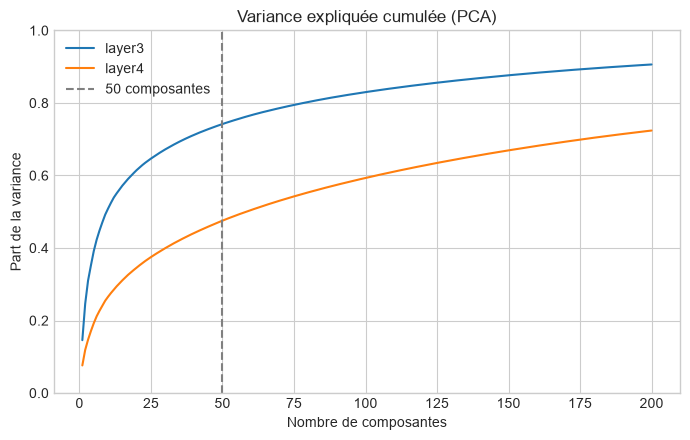

In [4]:
CURVE_COMPONENTS = 200

reduced = {}
variance = {}
for layer, matrix in scaled_features.items():
    curve = PCA(n_components=CURVE_COMPONENTS, random_state=RANDOM_STATE)
    curve.fit(matrix[is_train])
    variance[layer] = np.cumsum(curve.explained_variance_ratio_)

    reduced[layer] = reduce_with_pca(matrix, is_train)

checkpoints = [10, 20, 50, 100, 200]
display(
    pd.DataFrame(
        {
            layer: [curve[k - 1] for k in checkpoints]
            for layer, curve in variance.items()
        },
        index=[f"{k} composantes" for k in checkpoints],
    ).round(3)
)

figure, axis = plt.subplots(figsize=(7, 4.5))
for layer, curve in variance.items():
    axis.plot(np.arange(1, CURVE_COMPONENTS + 1), curve, label=layer)
axis.axvline(
    N_COMPONENTS,
    color="grey",
    linestyle="--",
    label=f"{N_COMPONENTS} composantes",
)
axis.set(
    title="Variance expliquée cumulée (PCA)",
    xlabel="Nombre de composantes",
    ylabel="Part de la variance",
    ylim=(0, 1),
)
axis.legend()
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "variance-expliquee-pca.png", dpi=120, bbox_inches="tight"
)
plt.show()

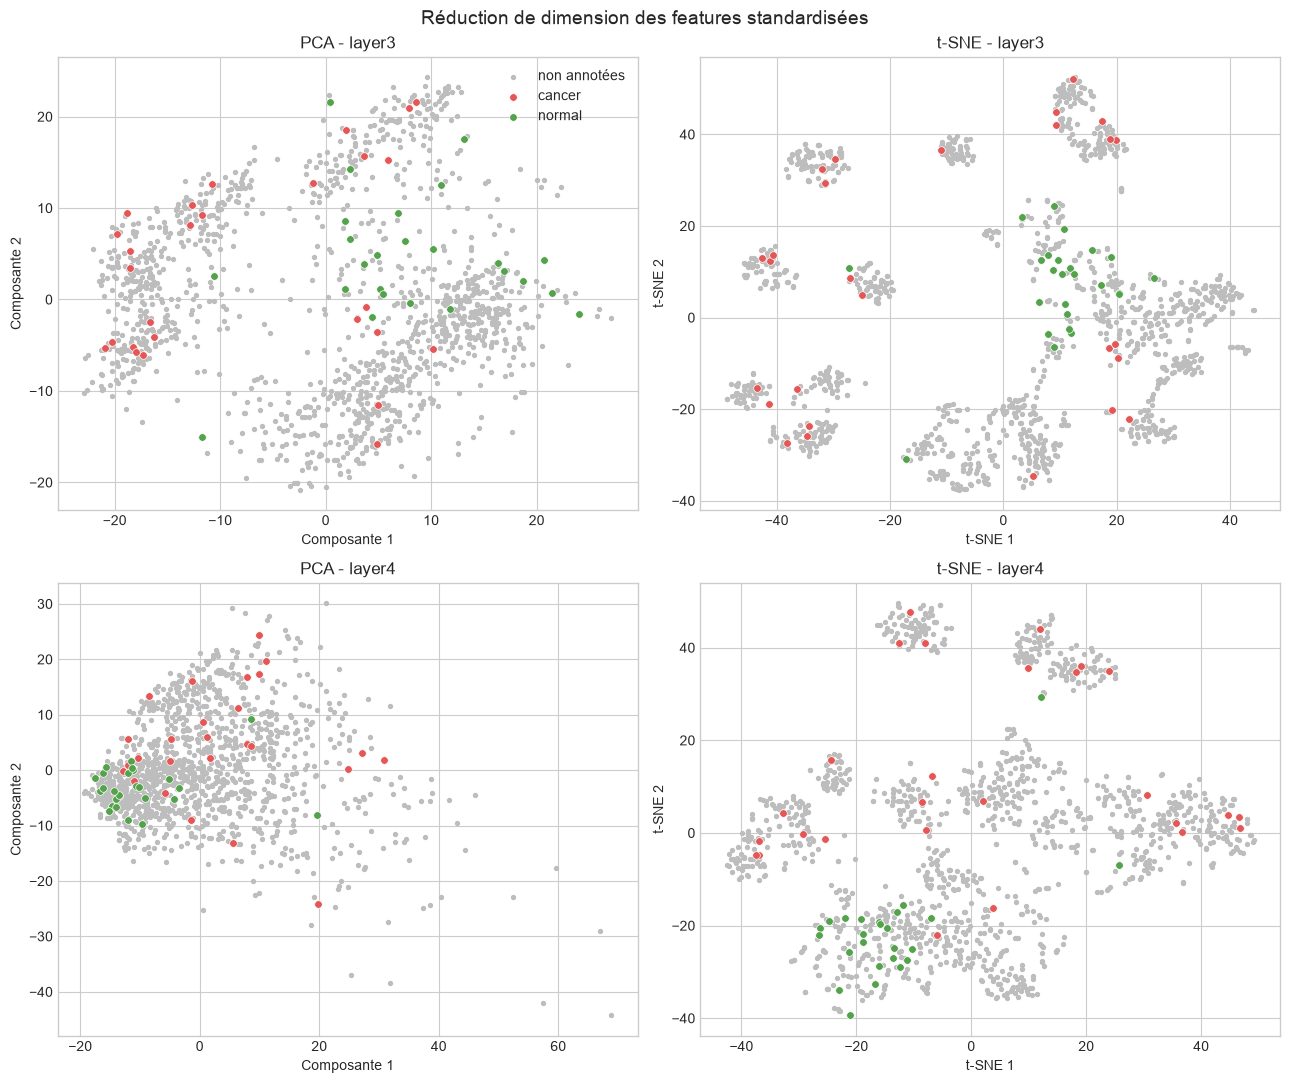

In [5]:
# Tableaux restreints à l'entraînement, utilisés pour le clustering.
train_labeled = is_labeled[is_train]
train_strong = strong_label[is_train]
train_reduced = {layer: matrix[is_train] for layer, matrix in reduced.items()}
train_scaled = {
    layer: matrix[is_train] for layer, matrix in scaled_features.items()
}

tsne_coordinates = {
    layer: TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        random_state=RANDOM_STATE,
    ).fit_transform(matrix)
    for layer, matrix in train_reduced.items()
}

LABEL_COLORS = ((1, "cancer", "#E45756"), (0, "normal", "#54A24B"))


def scatter_labels(axis, coordinates, title, xlabel, ylabel):
    """Nuage 2D : annotées colorées par label, non annotées en gris."""
    unlabeled = ~train_labeled
    axis.scatter(
        coordinates[unlabeled, 0],
        coordinates[unlabeled, 1],
        s=8,
        color="#BDBDBD",
        label="non annotées",
    )
    for value, name, color in LABEL_COLORS:
        mask = train_strong == value
        axis.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=30,
            color=color,
            edgecolor="white",
            linewidth=0.5,
            label=name,
        )
    axis.set(title=title, xlabel=xlabel, ylabel=ylabel)


figure, axes = plt.subplots(2, 2, figsize=(13, 11))
for row, layer in zip(axes, EXTRACTION_LAYERS, strict=True):
    scatter_labels(
        row[0],
        train_reduced[layer][:, :2],
        f"PCA - {layer}",
        "Composante 1",
        "Composante 2",
    )
    scatter_labels(
        row[1],
        tsne_coordinates[layer],
        f"t-SNE - {layer}",
        "t-SNE 1",
        "t-SNE 2",
    )
axes[0, 0].legend()
figure.suptitle(
    "Réduction de dimension des features standardisées", fontsize=14
)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "reduction-2d-labels.png", dpi=120, bbox_inches="tight"
)
plt.show()

## 5. Clustering

On cherche **deux groupes**, comme dans le jeu annoté. Trois méthodes sont comparées : K-Means, DBSCAN et HDBSCAN. Elles s'ajustent sur l'entraînement, **sans utiliser les labels**.

La qualité se mesure par l'**ARI** (*Adjusted Rand Index*) entre les clusters et les labels forts :

- 1 pour un accord parfait, **0 pour un accord équivalent au hasard**, négatif en dessous ;
- insensible au numéro attribué aux clusters.

L'ARI se calcule sur les **images annotées de l'entraînement** (52 images) : les images non annotées participent au clustering, mais n'ont pas de label pour être évaluées. Avec si peu d'images, les valeurs sont **indicatives**.

In [6]:
all_runs = []


def record(layer, method, parameters, cluster_labels, **extra):
    """Enregistre un clustering de l'entraînement et ses mesures."""
    labeled_clusters = cluster_labels[train_labeled]
    all_runs.append(
        {
            "couche": layer,
            "méthode": method,
            "paramètres": parameters,
            "clusters": len(set(cluster_labels) - {-1}),
            "bruit": float((cluster_labels == -1).mean()),
            "images évaluées": int((labeled_clusters != -1).sum()),
            "ARI hors bruit": ari_without_noise(
                labeled_clusters, train_strong[train_labeled]
            ),
            "labels": cluster_labels,
            **extra,
        }
    )

### K-Means

K-Means partitionne les images en `k = 2` groupes autour de centres. Il suppose des groupes compacts et de taille comparable, et part de centres tirés au hasard (le **seed**). On vérifie deux choses :

- le résultat **ne dépend pas du nombre de composantes** de la PCA : on compare 10, 20 et 50 composantes aux features standardisées complètes ;
- le résultat est **reproductible** : on relance 10 seeds et on compare chaque résultat au premier avec l'ARI. Un ARI de 1 signifie des clusters identiques. Ce contrôle mesure la stabilité, pas la qualité.

In [7]:
rows = []
for layer in EXTRACTION_LAYERS:
    spaces = {
        f"PCA {n}": train_reduced[layer][:, :n] for n in (10, 20, N_COMPONENTS)
    }
    spaces["features standardisées"] = train_scaled[layer]
    for space_name, space in spaces.items():
        model = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
        model.fit(space)
        rows.append(
            {
                "couche": layer,
                "espace": space_name,
                "ARI": ari_without_noise(
                    model.labels_[train_labeled], train_strong[train_labeled]
                ),
                "taille des clusters": np.bincount(model.labels_).tolist(),
                "silhouette": silhouette_score(space, model.labels_),
            }
        )
display(pd.DataFrame(rows).round(3))

for layer in EXTRACTION_LAYERS:
    model = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
    model.fit(train_reduced[layer])
    record(layer, "K-Means", {"k": 2}, model.labels_, model=model)

SEEDS = range(10)
for layer in EXTRACTION_LAYERS:
    runs = [
        KMeans(n_clusters=2, n_init=10, random_state=seed)
        .fit(train_reduced[layer])
        .labels_
        for seed in SEEDS
    ]
    stability = min(adjusted_rand_score(runs[0], other) for other in runs[1:])
    print(
        f"{layer} : ARI minimal entre le seed {SEEDS[0]} "
        f"et les {len(SEEDS) - 1} autres = {stability:.3f}"
    )

,couche,espace,ARI,taille des clusters,silhouette
0,layer3,PCA 10,0.199,"[874, 466]",0.240
1,layer3,PCA 20,0.199,"[875, 465]",0.196
2,layer3,PCA 50,0.199,"[464, 876]",0.160
3,layer3,features standardisées,0.199,"[464, 876]",0.117
4,layer4,PCA 10,0.106,"[439, 901]",0.253
5,layer4,PCA 20,0.106,"[436, 904]",0.224
6,layer4,PCA 50,0.106,"[433, 907]",0.207
7,layer4,features standardisées,0.106,"[423, 917]",0.152


layer3 : ARI minimal entre le seed 0 et les 9 autres = 1.000


layer4 : ARI minimal entre le seed 0 et les 9 autres = 0.964


### DBSCAN

DBSCAN regroupe les images situées dans une zone **dense** et laisse les autres de côté. Il ne demande pas le nombre de clusters, mais deux paramètres : `min_samples` (nombre de voisins requis pour qu'une image soit « dense ») et `eps` (rayon du voisinage).

Les images qu'aucun cluster n'accepte forment le **bruit** (`-1`). C'est un résultat **attendu** de la méthode, pas une anomalie : le bruit est rapporté (part des images), mais il n'est **ni un cluster, ni une classe**. L'ARI est calculé sur les images annotées qui appartiennent à un cluster (« ARI hors bruit »), avec le nombre d'images évaluées.

Pour choisir `eps`, on trace la **distance au `min_samples`-ième voisin**, triée : le « coude » sépare les images des zones denses (courbe plate) des images isolées (courbe qui monte).

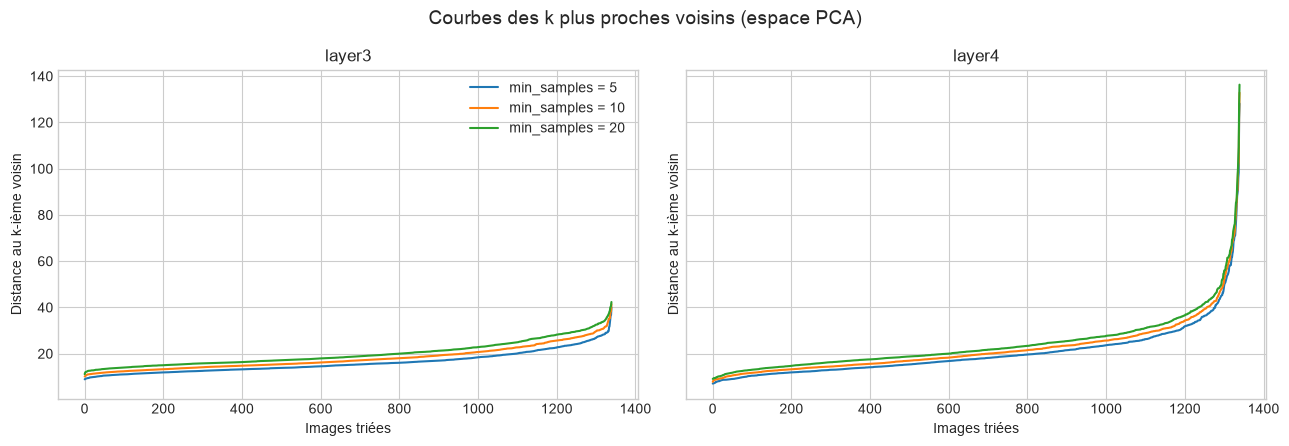

In [8]:
MIN_SAMPLES_VALUES = (5, 10, 20)

k_distances = {}
for layer in EXTRACTION_LAYERS:
    for min_samples in MIN_SAMPLES_VALUES:
        neighbors = NearestNeighbors(n_neighbors=min_samples)
        neighbors.fit(train_reduced[layer])
        distances, _ = neighbors.kneighbors(train_reduced[layer])
        k_distances[layer, min_samples] = np.sort(distances[:, -1])

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for axis, layer in zip(axes, EXTRACTION_LAYERS, strict=True):
    for min_samples in MIN_SAMPLES_VALUES:
        axis.plot(
            k_distances[layer, min_samples],
            label=f"min_samples = {min_samples}",
        )
    axis.set(
        title=layer, xlabel="Images triées", ylabel="Distance au k-ième voisin"
    )
axes[0].legend()
figure.suptitle("Courbes des k plus proches voisins (espace PCA)", fontsize=14)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "courbes-k-distance.png", dpi=120, bbox_inches="tight"
)
plt.show()

Sur `layer3`, la courbe monte progressivement, sans coude net ; sur `layer4`, elle ne décolle que pour une petite part d'images isolées. On balaie donc plusieurs valeurs de `eps`, choisies comme des **quantiles** de la courbe (70 %, 80 %, 90 % et 95 % des images ont leur k-ième voisin plus proche que `eps`).

In [9]:
EPS_QUANTILES = (0.7, 0.8, 0.9, 0.95)

for layer in EXTRACTION_LAYERS:
    for min_samples in MIN_SAMPLES_VALUES:
        for quantile in EPS_QUANTILES:
            eps = float(np.quantile(k_distances[layer, min_samples], quantile))
            model = DBSCAN(eps=eps, min_samples=min_samples)
            model.fit(train_reduced[layer])
            record(
                layer,
                "DBSCAN",
                {"min_samples": min_samples, "eps": round(eps, 1)},
                model.labels_,
            )

GRID_COLUMNS = [
    "couche",
    "paramètres",
    "clusters",
    "bruit",
    "images évaluées",
    "ARI hors bruit",
]
dbscan_grid = pd.DataFrame(all_runs).query("méthode == 'DBSCAN'")
display(
    dbscan_grid[GRID_COLUMNS]
    .sort_values(["couche", "ARI hors bruit"], ascending=[True, False])
    .round(3)
    .reset_index(drop=True)
)

,couche,paramètres,clusters,bruit,images évaluées,ARI hors bruit
0,layer3,"{'min_samples': 5, 'eps': 17.4}",13,0.222,31,0.180
1,layer3,"{'min_samples': 5, 'eps': 22.8}",5,0.048,47,0.000
2,layer3,"{'min_samples': 5, 'eps': 25.2}",3,0.018,51,0.000
3,layer3,"{'min_samples': 10, 'eps': 25.8}",1,0.031,50,0.000
4,layer3,"{'min_samples': 10, 'eps': 27.9}",1,0.013,52,0.000
5,layer3,"{'min_samples': 20, 'eps': 24.3}",1,0.102,41,0.000
6,layer3,"{'min_samples': 20, 'eps': 28.4}",1,0.019,52,0.000
7,layer3,"{'min_samples': 20, 'eps': 30.4}",1,0.006,52,0.000
8,layer3,"{'min_samples': 10, 'eps': 22.1}",3,0.122,41,-0.011
9,layer3,"{'min_samples': 10, 'eps': 19.7}",5,0.191,31,-0.032


### HDBSCAN

HDBSCAN (*Hierarchical* DBSCAN) lance DBSCAN pour **tous les rayons possibles** et retient les groupes les plus persistants. Il gère des groupes de densités différentes, et son paramètre principal est `min_cluster_size` (taille minimale d'un groupe) au lieu d'`eps`. Comme DBSCAN, il laisse du **bruit** (`-1`), traité de la même façon.

In [10]:
MIN_CLUSTER_SIZES = (10, 20, 50, 100)
HDBSCAN_MIN_SAMPLES = (None, 5, 10)

for layer in EXTRACTION_LAYERS:
    for min_cluster_size in MIN_CLUSTER_SIZES:
        for min_samples in HDBSCAN_MIN_SAMPLES:
            model = HDBSCAN(
                min_cluster_size=min_cluster_size,
                min_samples=min_samples,
                copy=True,
            )
            model.fit(train_reduced[layer])
            record(
                layer,
                "HDBSCAN",
                {
                    "min_cluster_size": min_cluster_size,
                    "min_samples": min_samples,
                },
                model.labels_,
            )

hdbscan_grid = pd.DataFrame(all_runs).query("méthode == 'HDBSCAN'")
display(
    hdbscan_grid[GRID_COLUMNS]
    .sort_values(["couche", "ARI hors bruit"], ascending=[True, False])
    .round(3)
    .reset_index(drop=True)
)

,couche,paramètres,clusters,bruit,images évaluées,ARI hors bruit
0,layer3,"{'min_cluster_size': 100, 'min_samples': 5}",5,0.279,28,0.164
1,layer3,"{'min_cluster_size': 50, 'min_samples': 5}",7,0.284,28,0.105
2,layer3,"{'min_cluster_size': 10, 'min_samples': 5}",11,0.287,29,0.101
3,layer3,"{'min_cluster_size': 20, 'min_samples': 5}",8,0.284,28,0.089
4,layer3,"{'min_cluster_size': 50, 'min_samples': None}",2,0.306,25,-0.047
5,layer3,"{'min_cluster_size': 50, 'min_samples': 10}",2,0.160,34,-0.071
6,layer3,"{'min_cluster_size': 100, 'min_samples': 10}",2,0.160,34,-0.071
7,layer3,"{'min_cluster_size': 20, 'min_samples': None}",3,0.224,27,-0.088
8,layer3,"{'min_cluster_size': 20, 'min_samples': 10}",3,0.170,33,-0.124
9,layer3,"{'min_cluster_size': 10, 'min_samples': None}",11,0.415,21,NaN


### Comparaison des méthodes

Les méthodes sont comparées sur la couche de référence, `layer3`, retenue à l'étape précédente. Pour DBSCAN et HDBSCAN, on retient la configuration de la grille qui a **au moins deux clusters**, **au plus 30 % de bruit** et le meilleur ARI hors bruit : une méthode qui écarte la moitié des images n'est pas utilisable. Cette sélection sert à **illustrer** les méthodes par densité. Elle repose sur peu d'images, et K-Means, qui n'a pas de paramètre à choisir, reste la référence.

On mesure aussi la **cohérence entre méthodes** : l'ARI entre les partitions de deux méthodes, sur les images de l'entraînement qu'aucune des deux n'a classées en bruit. Un ARI proche de 0 signifie que les deux méthodes ne retrouvent pas la même structure.

In [11]:
MAX_NOISE = 0.30

results = pd.DataFrame(all_runs)
candidates = results[
    (results["couche"] == REFERENCE_LAYER)
    & (results["méthode"] != "K-Means")
    & (results["clusters"] >= 2)
    & (results["bruit"] <= MAX_NOISE)
]
selected = candidates.loc[
    candidates.groupby("méthode")["ARI hors bruit"].idxmax()
]
reference = results[
    (results["couche"] == REFERENCE_LAYER) & (results["méthode"] == "K-Means")
]
comparison_runs = pd.concat([reference, selected]).reset_index(drop=True)

display(
    comparison_runs[
        [
            "méthode",
            "paramètres",
            "clusters",
            "bruit",
            "images évaluées",
            "ARI hors bruit",
        ]
    ].round(3)
)

methods = comparison_runs["méthode"].tolist()
agreement = pd.DataFrame(index=methods, columns=methods, dtype=float)
for first, run_a in comparison_runs.set_index("méthode").iterrows():
    for second, run_b in comparison_runs.set_index("méthode").iterrows():
        kept = (run_a["labels"] != -1) & (run_b["labels"] != -1)
        agreement.loc[first, second] = adjusted_rand_score(
            run_a["labels"][kept], run_b["labels"][kept]
        )
display(agreement.round(3))

,méthode,paramètres,clusters,bruit,images évaluées,ARI hors bruit
0,K-Means,{'k': 2},2,0.000,52,0.199
1,DBSCAN,"{'min_samples': 5, 'eps': 17.4}",13,0.222,31,0.180
2,HDBSCAN,"{'min_cluster_size': 100, 'min_samples': 5}",5,0.279,28,0.164


,K-Means,DBSCAN,HDBSCAN
K-Means,1.000,0.327,0.344
DBSCAN,0.327,1.000,0.954
HDBSCAN,0.344,0.954,1.000


Chaque méthode est représentée avec sa configuration retenue, sur la PCA (ligne du haut) et sur le t-SNE (ligne du bas) de la couche de référence. Les points gris sont du bruit.

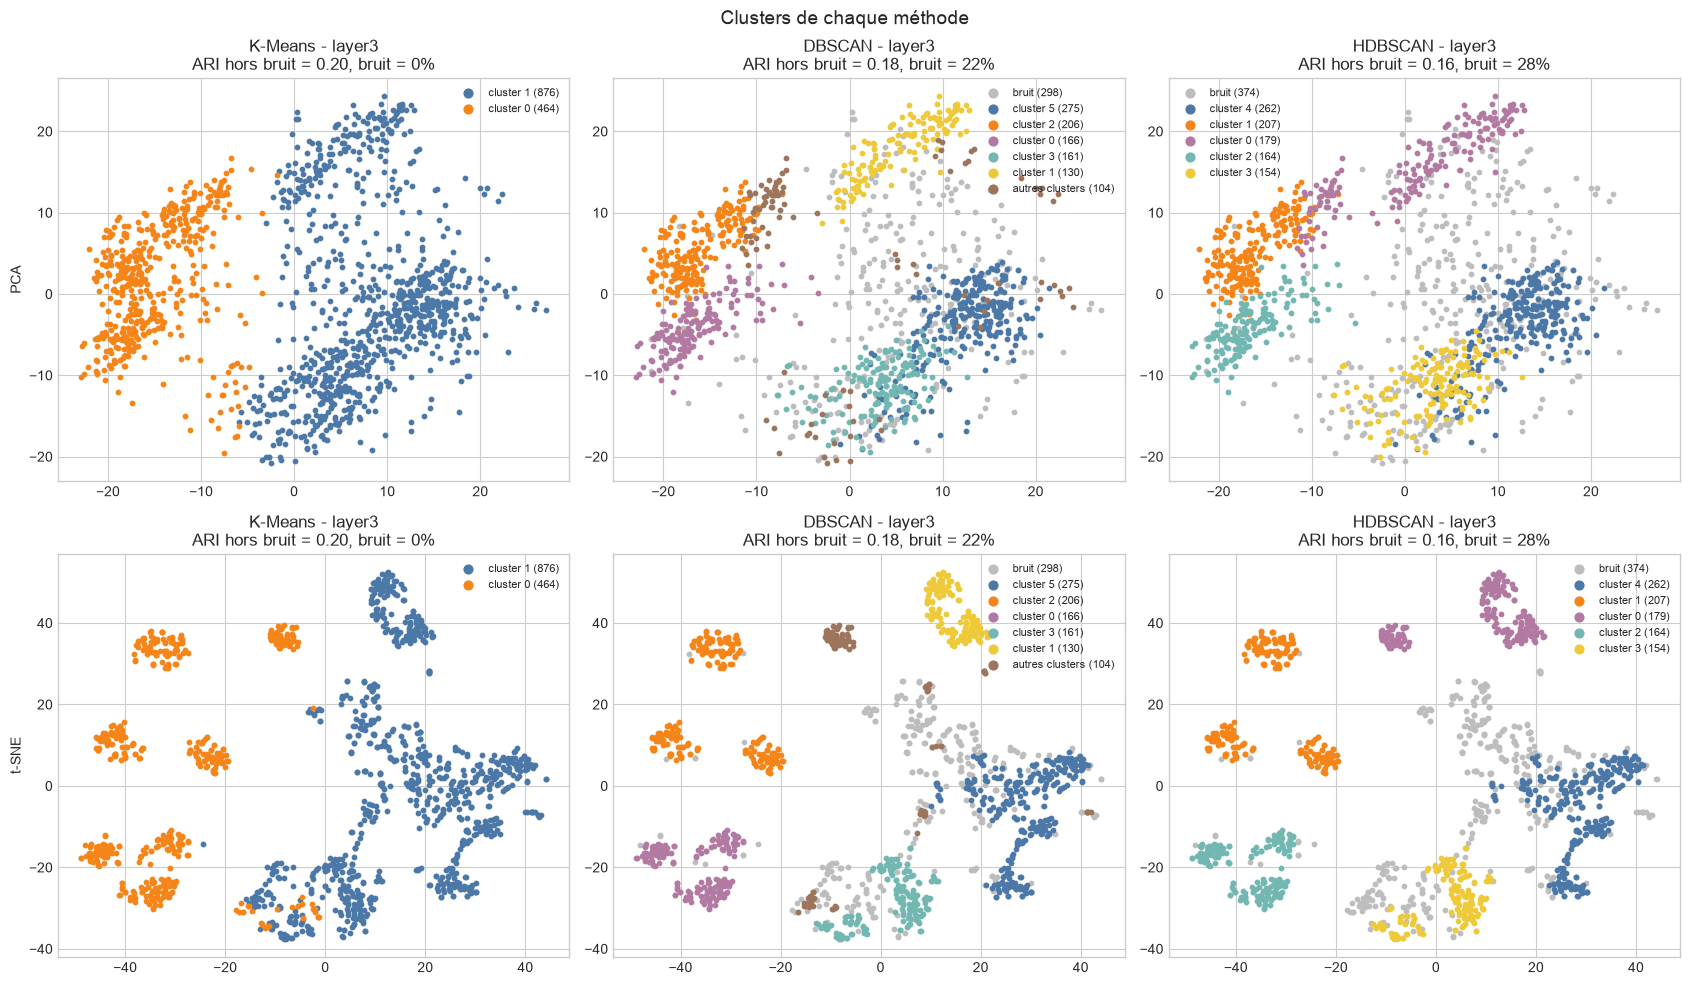

In [12]:
CLUSTER_COLORS = ["#4C78A8", "#F58518", "#B279A2", "#72B7B2", "#EECA3B"]
OTHER_COLOR = "#9D755D"
NOISE_COLOR = "#BDBDBD"


def scatter_clusters(axis, coordinates, cluster_labels, title):
    """Nuage 2D : les plus gros clusters en couleur, le bruit en gris."""
    clustered = cluster_labels[cluster_labels != -1]
    clusters, sizes = np.unique(clustered, return_counts=True)
    largest = clusters[np.argsort(-sizes)][: len(CLUSTER_COLORS)]
    groups = []
    if (cluster_labels == -1).any():
        groups.append((cluster_labels == -1, NOISE_COLOR, "bruit"))
    for cluster, color in zip(largest, CLUSTER_COLORS, strict=False):
        groups.append((cluster_labels == cluster, color, f"cluster {cluster}"))
    others = (cluster_labels != -1) & ~np.isin(cluster_labels, largest)
    if others.any():
        groups.append((others, OTHER_COLOR, "autres clusters"))
    for mask, color, name in groups:
        axis.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=10,
            color=color,
            label=f"{name} ({mask.sum()})",
        )
    axis.set_title(title)
    axis.legend(markerscale=2, fontsize=8)


figure, axes = plt.subplots(2, 3, figsize=(17, 10))
for column, (_, run) in enumerate(comparison_runs.iterrows()):
    title = (
        f"{run['méthode']} - {run['couche']}\n"
        f"ARI hors bruit = {run['ARI hors bruit']:.2f}, "
        f"bruit = {run['bruit']:.0%}"
    )
    scatter_clusters(
        axes[0, column],
        train_reduced[run["couche"]][:, :2],
        run["labels"],
        title,
    )
    scatter_clusters(
        axes[1, column], tsne_coordinates[run["couche"]], run["labels"], title
    )
axes[0, 0].set_ylabel("PCA")
axes[1, 0].set_ylabel("t-SNE")
figure.suptitle("Clusters de chaque méthode", fontsize=14)
plt.tight_layout()
figure.savefig(FIGURES_DIR / "clusters-2d.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Labels faibles

Un cluster n'a pas de sens médical : il faut lui associer une classe. On attribue à chaque cluster de K-Means la classe **majoritaire** parmi ses images annotées de l'entraînement (égalité : `normal`), puis ce label faible à toutes les images du cluster. Pour mesurer la fiabilité d'une attribution, on calcule une **confiance** : la marge relative entre la distance au centre le plus proche et la distance à l'autre centre (0 = à égale distance des deux centres, 1 = sur le centre).

Seul K-Means fournit des labels faibles. Les images laissées en bruit par DBSCAN et HDBSCAN n'auraient pas de classe : ces méthodes servent à la comparaison, pas à étiqueter.

Le vote, la confiance et la construction des labels faibles sont implémentés dans `brain_mri.modeling.unsupervised`. Les labels faibles des images **non annotées** sont exportés dans `data/processed/weak_labels.csv`, un fichier séparé du jeu annoté.

In [13]:
kmeans_run = reference.iloc[0]
mapping = majority_mapping(kmeans_run["labels"], train_strong, train_labeled)
print(f"Cluster → classe (1 = cancer, 0 = normal) : {mapping}")

train_manifest = manifest[is_train].reset_index(drop=True)
train_weak = to_weak_labels(kmeans_run["labels"], mapping)
weak_labels = build_weak_labels(
    train_manifest,
    kmeans_run["labels"],
    mapping,
    kmeans_confidence(kmeans_run["model"], train_reduced[REFERENCE_LAYER]),
)
weak_labels.to_csv(PROCESSED_DATA_DIR / "weak_labels.csv", index=False)

assert len(weak_labels) == (~manifest["is_labeled"]).sum()
assert weak_labels["weak_label"].notna().all()
display(weak_labels["weak_label"].value_counts().rename("images").to_frame())

Cluster → classe (1 = cancer, 0 = normal) : {np.int32(0): 1, np.int32(1): 0}


,images
weak_label,
normal,841
cancer,447


## 7. Évaluation sur la validation et le test

Les images de validation et de test n'ont servi ni à ajuster, ni à choisir quoi que ce soit. On leur attribue un cluster avec les mêmes règles que pour l'entraînement :

- K-Means les rattache au centre le plus proche (`predict`) ;
- DBSCAN et HDBSCAN n'ont pas de `predict` : une image prend le groupe de son **plus proche voisin** de l'entraînement, bruit compris (elle reste donc du bruit si ce voisin en est).

On mesure l'ARI (hors bruit pour DBSCAN et HDBSCAN, avec le nombre d'images évaluées) et, pour K-Means, l'**exactitude du label faible** : la part de labels faibles égaux au label fort. Sur l'entraînement, cette exactitude est **optimiste**, car le vote a utilisé ces mêmes images. Avec 16 images de validation et 30 de test, une image représente plusieurs points d'exactitude : ces mesures sont indicatives.

In [14]:
def assign_clusters(run, mask):
    """Clusters des images de `mask`, avec les règles de la méthode."""
    space = reduced[run["couche"]]
    if run["méthode"] == "K-Means":
        return run["model"].predict(space[mask])
    nearest = KNeighborsClassifier(n_neighbors=1)
    nearest.fit(space[is_train], run["labels"])
    return nearest.predict(space[mask])


rows = []
for _, run in comparison_runs.iterrows():
    for split_name, mask in (("validation", is_validation), ("test", is_test)):
        clusters = assign_clusters(run, mask)
        rows.append(
            {
                "méthode": run["méthode"],
                "jeu": split_name,
                "bruit": float((clusters == -1).mean()),
                "images évaluées": int((clusters != -1).sum()),
                "ARI hors bruit": ari_without_noise(
                    clusters, strong_label[mask]
                ),
            }
        )
display(pd.DataFrame(rows).round(3))

kmeans_clusters = {
    "entraînement (optimiste)": kmeans_run["labels"][train_labeled],
    "validation": assign_clusters(kmeans_run, is_validation),
    "test": assign_clusters(kmeans_run, is_test),
}
true_labels = {
    "entraînement (optimiste)": train_strong[train_labeled],
    "validation": strong_label[is_validation],
    "test": strong_label[is_test],
}
display(
    pd.DataFrame(
        {
            split_name: {
                "images": len(clusters),
                "exactitude du label faible": (
                    to_weak_labels(clusters, mapping) == true_labels[split_name]
                ).mean(),
            }
            for split_name, clusters in kmeans_clusters.items()
        }
    ).T.round(3)
)

,méthode,jeu,bruit,images évaluées,ARI hors bruit
0,K-Means,validation,0.000,16,0.354
1,K-Means,test,0.000,30,0.341
2,DBSCAN,validation,0.250,12,0.253
3,DBSCAN,test,0.367,19,0.023
4,HDBSCAN,validation,0.312,11,0.182
5,HDBSCAN,test,0.433,17,-0.013


,images,exactitude du label faible
entraînement (optimiste),52.0,0.731
validation,16.0,0.812
test,30.0,0.800


### Quelles erreurs fait le label faible ?

L'exactitude ne dit pas quelle classe est mal étiquetée. On détaille donc les erreurs de K-Means sur la validation et le test :

- la **matrice de confusion** compte, pour chaque label fort, les labels faibles attribués ;
- la **précision** d'une classe est la part des images étiquetées dans cette classe qui y appartiennent vraiment ;
- le **rappel** d'une classe est la part des images de cette classe qui ont reçu le bon label faible. En contexte médical, le rappel de `cancer` compte : un cancer étiqueté `normal` est l'erreur la plus grave ;
- le **F1** est la moyenne harmonique de la précision et du rappel ;
- l'**exactitude équilibrée** est la moyenne des rappels des deux classes ;
- l'**intervalle de confiance à 95 %** de l'exactitude (méthode de Wilson) traduit l'incertitude due au petit nombre d'images.

Avec 16 et 30 images, ces mesures restent indicatives. Elles sont calculées par `evaluate_weak_labels` (`brain_mri.modeling.unsupervised`).

In [15]:
confusion_tables = {}
class_tables = {}
summary_rows = []
for split_name, mask in (("validation", is_validation), ("test", is_test)):
    expected = strong_label[mask].astype(int)
    predicted = to_weak_labels(
        assign_clusters(kmeans_run, mask), mapping
    ).astype(int)
    evaluation = evaluate_weak_labels(expected, predicted)
    confusion_tables[split_name] = evaluation.confusion
    class_tables[split_name] = evaluation.per_class
    summary_rows.append({"jeu": split_name, **evaluation.summary})

for split_name, table in confusion_tables.items():
    print(f"Matrice de confusion - {split_name}")
    display(table)

display(pd.concat(class_tables, names=["jeu"]).round(3))
display(pd.DataFrame(summary_rows).set_index("jeu").round(3))

Matrice de confusion - validation


label faible,cancer,normal
label fort,,
cancer,5,3
normal,0,8


Matrice de confusion - test


label faible,cancer,normal
label fort,,
cancer,9,6
normal,0,15


précision  rappel     F1  images
jeu        classe                                  
validation cancer      1.000   0.625  0.769       8
           normal      0.727   1.000  0.842       8
test       cancer      1.000   0.600  0.750      15
           normal      0.714   1.000  0.833      15

,images,exactitude,IC 95 % bas,IC 95 % haut,exactitude équilibrée
jeu,,,,,
validation,16,0.812,0.570,0.934,0.812
test,30,0.800,0.627,0.905,0.800


## 8. Fiabilité des labels faibles

### Que capturent les clusters ?

Le notebook `03.0` a montré que des indices d'acquisition (luminosité, contraste, part de fond noir) séparent en partie `cancer` et `normal`, malgré l'égalisation. Les clusters pourraient suivre ces indices plutôt que la pathologie, et les labels faibles hériteraient du biais.

On mesure donc, sur les **images d'origine** (non égalisées), l'**AUC** de chaque descripteur pour prédire :

- le **label fort**, sur les annotées de l'entraînement ;
- le **label faible** de K-Means, sur les images de l'entraînement.

Une AUC de 0,5 signifie que le descripteur ne sépare pas du tout les classes. Si l'AUC du label faible est plus éloignée de 0,5 que celle du label fort, le clustering exploite davantage cet indice que ne le fait la pathologie.

In [16]:
BACKGROUND_LEVEL = 10


def describe_image(filepath):
    """Luminosité, contraste et part de fond de l'image d'origine."""
    with Image.open(filepath) as image:
        gray = np.asarray(image.convert("L"), dtype=float)
    return {
        "luminosité": gray.mean(),
        "contraste": gray.std(),
        "part de fond": (gray < BACKGROUND_LEVEL).mean(),
    }


descriptors = pd.DataFrame(
    [describe_image(path) for path in manifest["filepath"]]
)
train_descriptors = descriptors[is_train].reset_index(drop=True)


def descriptor_auc(binary_labels):
    """AUC de chaque descripteur pour prédire un label binaire."""
    known = ~np.isnan(binary_labels)
    return train_descriptors[known].apply(
        lambda column: roc_auc_score(binary_labels[known], column)
    )


display(
    pd.DataFrame(
        {
            "label fort (annotées)": descriptor_auc(
                np.where(train_labeled, train_strong, np.nan)
            ),
            "label faible K-Means": descriptor_auc(train_weak),
        }
    ).round(3)
)

,label fort (annotées),label faible K-Means
luminosité,0.347,0.448
contraste,0.236,0.272
part de fond,0.578,0.328


### La répartition des labels faibles est-elle plausible ?

On compare la part de `cancer` parmi les labels faibles à celle des images annotées de l'entraînement, et on regarde la distribution de la confiance. Les images annotées sont équilibrées à deux images près, mais la répartition des images non annotées est **inconnue** : cette comparaison ne démontre rien, elle signale un écart éventuel.

In [17]:
share = pd.Series(
    {
        "annotées de l'entraînement (labels forts)": np.nanmean(
            train_strong[train_labeled]
        ),
        "non annotées (labels faibles)": (
            weak_labels["weak_label"] == "cancer"
        ).mean(),
    },
    name="part de cancer",
)
display(share.to_frame().round(3))

display(weak_labels.groupby("weak_label")["confidence"].describe().round(3))

,part de cancer
annotées de l'entraînement (labels forts),0.519
non annotées (labels faibles),0.347


,count,mean,std,min,25%,50%,75%,max
weak_label,,,,,,,,
cancer,447.0,0.182,0.075,0.002,0.123,0.202,0.238,0.328
normal,841.0,0.151,0.074,0.002,0.096,0.144,0.204,0.369


### Les clusters de K-Means recoupent-ils les labels forts ?

On projette sur les deux premières composantes de la PCA les clusters de K-Means (à gauche) et les labels forts des images annotées de l'entraînement (à droite), les images non annotées restant en gris. Les croix noires marquent les **centres** des deux clusters, projetés sur les mêmes axes : en dimension 50, deux points proches sur ce plan peuvent être éloignés dans l'espace complet, et la frontière entre clusters n'est pas visible en 2D.

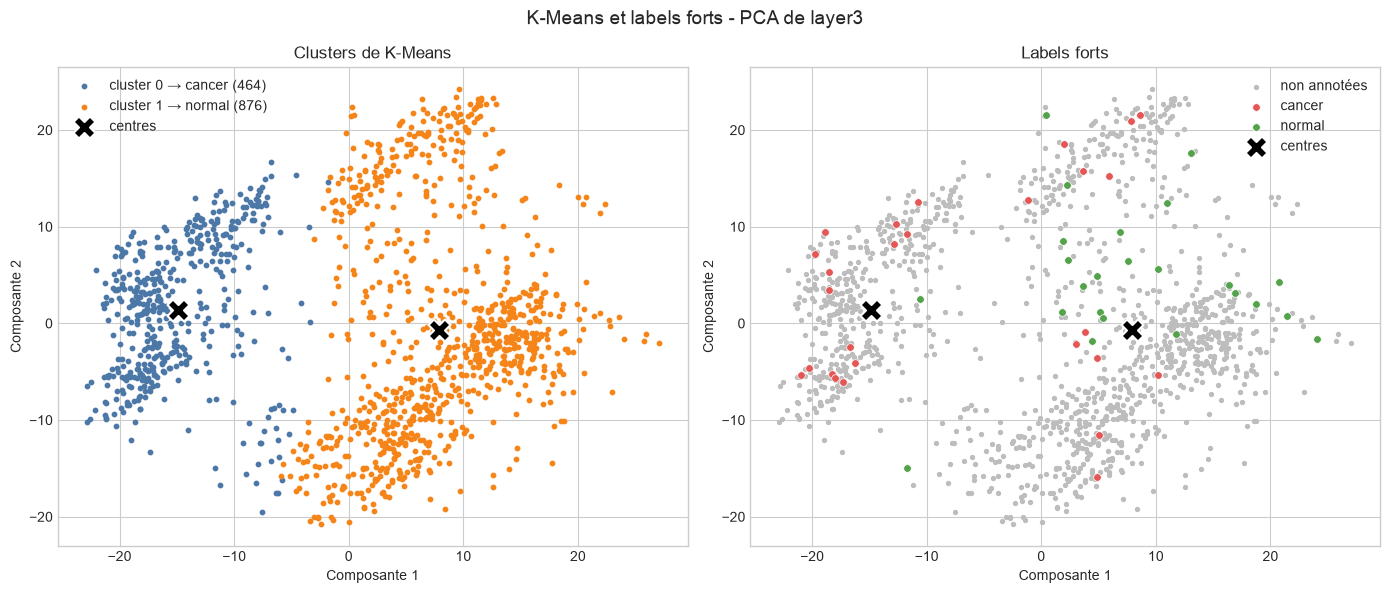

In [18]:
CLASS_NAMES = {1: "cancer", 0: "normal"}
KMEANS_COLORS = ["#4C78A8", "#F58518"]

coordinates = train_reduced[REFERENCE_LAYER][:, :2]
centers = kmeans_run["model"].cluster_centers_[:, :2]

figure, axes = plt.subplots(1, 2, figsize=(14, 6))

for cluster, color in zip(sorted(mapping), KMEANS_COLORS, strict=True):
    mask = kmeans_run["labels"] == cluster
    axes[0].scatter(
        coordinates[mask, 0],
        coordinates[mask, 1],
        s=10,
        color=color,
        label=(
            f"cluster {cluster} → {CLASS_NAMES[mapping[cluster]]} "
            f"({mask.sum()})"
        ),
    )
axes[0].set_title("Clusters de K-Means")

scatter_labels(
    axes[1], coordinates, "Labels forts", "Composante 1", "Composante 2"
)

for axis in axes:
    axis.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="X",
        s=250,
        color="black",
        edgecolor="white",
        linewidth=1.5,
        label="centres",
        zorder=3,
    )
    axis.set(xlabel="Composante 1", ylabel="Composante 2")
    axis.legend()

figure.suptitle(
    f"K-Means et labels forts - PCA de {REFERENCE_LAYER}", fontsize=14
)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "kmeans-clusters-labels.png", dpi=120, bbox_inches="tight"
)
plt.show()

## Conclusion de l'étape

### Synthèse

- **Découpage.** L'entraînement compte 1 340 images (52 annotées, dont 27 `cancer` et 25 `normal`, et 1 288 non annotées), la validation 16 images (8 + 8) et le test 30 images (15 + 15). Les trois jeux sont disjoints et définis avant toute transformation. La standardisation et la PCA sont ajustées sur l'entraînement seul : les 50 composantes retenues portent **74 %** de la variance pour `layer3` et **47,5 %** pour `layer4`.
- **Structure visible.** Sur `layer3`, les `cancer` annotées se trouvent surtout dans des **îlots compacts** et les `normal` dans une zone plus diffuse ; sur `layer4`, les classes se mélangent davantage. Ces îlots regroupent des images très proches les unes des autres (même coupe ou même série ?). Faute de métadonnées, on ne peut pas le vérifier.
- **`layer3` est la meilleure couche.** K-Means y obtient un ARI de **0,199**, contre **0,106** sur `layer4`. Sur `layer4`, DBSCAN ne forme qu'un seul cluster et HDBSCAN laisse au moins 44 % des images en bruit.

La comparaison des trois méthodes sur `layer3` donne (ARI hors bruit pour DBSCAN et HDBSCAN) :

| Méthode | Clusters | Bruit à l'entraînement | ARI entraînement | ARI validation | ARI test |
|---|---|---|---|---|---|
| K-Means | 2 | 0 % | 0,199 | 0,354 | 0,341 |
| DBSCAN | 13 | 22 % | 0,180 | 0,253 | 0,023 |
| HDBSCAN | 5 | 28 % | 0,164 | 0,182 | -0,013 |

- **K-Means** est stable : même résultat pour 10, 20 et 50 composantes comme pour les features complètes, et pour 10 seeds (ARI minimal de 1,000 sur `layer3`, 0,964 sur `layer4`). Un ARI d'environ 0,2 est meilleur que le hasard (0) mais loin d'un accord parfait (1). Ses clusters comptent 464 et 876 images.
- **DBSCAN et HDBSCAN** laissent du bruit, ce qui est attendu : 22 % et 28 % des images à l'entraînement, et 25 à 43 % sur la validation et le test. Leur ARI hors bruit tombe à environ 0 sur le test, alors que celui de K-Means se maintient. Cet écart est à relativiser : leur configuration a été choisie parmi 24 sur l'entraînement, et l'ARI est calculé sur très peu d'images (31 et 28 à l'entraînement, 12 et 11 sur la validation, 19 et 17 sur le test).
- **Cohérence entre méthodes.** DBSCAN et HDBSCAN retrouvent presque la même structure (ARI de **0,954**), alors que K-Means n'en retrouve qu'une partie (**0,327** et **0,344**).
- **Labels faibles.** Les 1 288 images non annotées reçoivent **841 `normal` et 447 `cancer`**, soit 35 % de `cancer` contre 52 % parmi les annotées de l'entraînement. La répartition réelle des non annotées est inconnue : cet écart est un signal, pas une preuve.
- **Exactitude du label faible** (K-Means) : **0,731** sur l'entraînement (optimiste, le vote utilise ces images), **0,812** sur la validation (13 images sur 16) et **0,800** sur le test (24 sur 30).
- **Confiance.** Elle est faible : médiane de **0,20** pour `cancer` et **0,14** pour `normal`, maximum de **0,37**. Aucune image n'est proche d'un centre par rapport à l'autre, ce qui confirme que les deux clusters sont mal séparés.

### Décision

**K-Means** (couche `layer3`, 50 composantes, `k = 2`, seed fixe) est la référence et la **seule source de labels faibles**, pour quatre raisons :

1. il attribue une classe à **toutes** les images, alors que DBSCAN et HDBSCAN laissent 22 % et 28 % des images sans cluster, donc sans classe ;
2. il produit directement **deux groupes**, comme les deux classes du jeu annoté ;
3. son ARI **se maintient** sur la validation et le test ;
4. il n'a **aucun paramètre à choisir** sur 52 images.

DBSCAN et HDBSCAN restent dans le notebook à titre de comparaison : ils montrent que le jeu contient des zones denses (les îlots), mais leur accord avec les labels forts n'est pas confirmé sur des images jamais vues.

À l'étape suivante, les labels faibles sont à utiliser avec prudence : exactitude d'environ 0,80 sur des images jamais vues, confiance faible, proportion de `cancer` non vérifiable, dépendance partielle à la part de fond et jeu annoté non parfaitement représentatif. Le jeu de validation (16 images) sert à l'arrêt anticipé, le modèle semi-supervisé est comparé à un modèle entraîné **sans** labels faibles, et un seuil de confiance ainsi qu'une augmentation de luminosité et de contraste sont à essayer.